# Titanic: Exploring Survival Patterns

## Exploratory Data Analysis
**Objective:** Explore the Titanic passenger dataset and investigate whether survival was associated with passenger class, gender, and age.
Rather than looking only at how many passengers survived, this notebook compares survival rates across groups. This matters because groups may contain different numbers of passengers.

Three possible hypotheses that can define this dataset:
1. Is survival associated with passenger class?
2. Is survival associated with gender?
3. Is survival associated with age?

## 1. Prepare the Data
Before testing my hypotheses, I need to understand what one row represents, which variables are available, and whether any information is missing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
import os
os.makedirs("../RESULTS", exist_ok=True)

DATA_PATH = "../DATA/train.csv"

# Read the dataset
titanic = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {titanic.shape[0]} rows × {titanic.shape[1]} columns")
display(titanic.head())

# A consistent style for the whole notebook
sns.set_theme(style="white", context="notebook")
YELLOW = "#F4C045"
BLUE = "#2878B5"
ORANGE = "#E07A3F"
GREEN = "#4A9D75"
GREY = "#777777"

Dataset shape: 891 rows × 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Column names and data types
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
# Summary statistics for numerical columns
display(titanic.describe().round(2))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [4]:
# Number and percentage of missing values in each column
missing_summary = pd.DataFrame({
    "Missing values": titanic.isna().sum(),
    "Missing (%)": (titanic.isna().mean() * 100).round(1)
}).sort_values("Missing (%)", ascending=False)

display(missing_summary[missing_summary["Missing values"] > 0])

,Missing values,Missing (%)
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


*Cabin (77.1% missing) is not used in this analysis. Age (19.9% missing) is not imputed, because filling with the median would distort the age distribution; the age analysis uses only the 714 passengers with a recorded age. Embarked is not used.*

## 2. Hypothesis 1 - Passenger class and survival
**Research question:** Is survival associated with passenger class?
- H₀: Passenger class and survival are independent.
- H₁: Passenger class and survival are associated.
I will compare survival rates across the three passenger classes and use a chi-square test of independence.

In [5]:
class_summary = (
    titanic.groupby("Pclass")["Survived"]
    .agg(Passengers="count", Survivors="sum", Survival_rate="mean")
    .reset_index()
)
class_summary["Non-survivors"] = class_summary["Passengers"] - class_summary["Survivors"]
class_summary["Survival (%)"] = (class_summary["Survival_rate"] * 100).round(1)
class_summary["Class"] = class_summary["Pclass"].map({1: "1st class", 2: "2nd class", 3: "3rd class"})
display(class_summary[["Class", "Passengers", "Survivors", "Non-survivors", "Survival (%)"]])

,Class,Passengers,Survivors,Non-survivors,Survival (%)
0,1st class,216,136,80,63.0
1,2nd class,184,87,97,47.3
2,3rd class,491,119,372,24.2


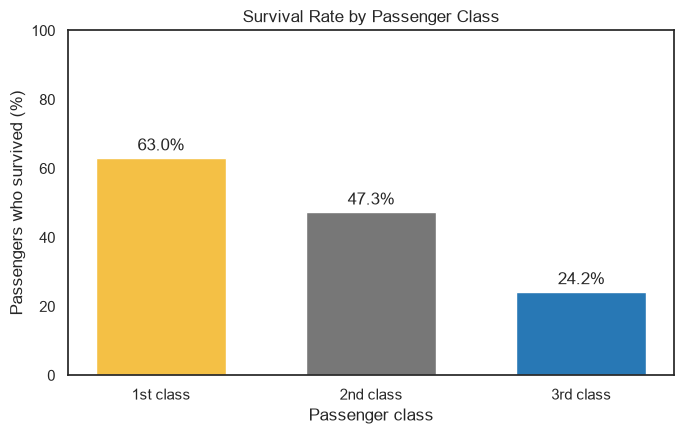

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(class_summary["Class"], class_summary["Survival (%)"],
              color=[YELLOW, GREY, BLUE], width=0.62)
ax.set_title("Survival Rate by Passenger Class")
ax.set_xlabel("Passenger class")
ax.set_ylabel("Passengers who survived (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in class_summary["Survival (%)"]], padding=3)
plt.tight_layout()
plt.savefig("../RESULTS/Survival_by_class.png", dpi=150)
plt.show()

In [7]:
class_table = pd.crosstab(titanic["Pclass"], titanic["Survived"])
class_chi2, class_p, class_dof, class_expected = stats.chi2_contingency(class_table)
n = class_table.to_numpy().sum()
r, k = class_table.shape
class_cramers_v = np.sqrt(class_chi2 / (n * min(r - 1, k - 1)))

print("Observed counts (rows = passenger class; columns = survival outcome):")
display(class_table)
print(f"Chi-square statistic: {class_chi2:.3f}")
print(f"Degrees of freedom: {class_dof}")
print(f"p-value: {class_p:.6g}")
print(f"Cramér's V: {class_cramers_v:.3f}")

Observed counts (rows = passenger class; columns = survival outcome):


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


Chi-square statistic: 102.889
Degrees of freedom: 2
p-value: 4.54925e-23
Cramér's V: 0.340


The chi-square test gave a p-value far below 0.05 (p < 0.001), so I reject the null hypothesis that survival is independent of class. Cramér’s V (0.34) indicates a moderate association.

### Interpretation:
The results show that passenger class was associated with survival. First-class passengers had the highest survival rate (63.0%), while third-class passengers had the lowest (24.2%), meaning first-class passengers were about 2.6 times more likely to survive.

## 3. Hypothesis 2 - Recorded sex and survival
**Research question:** Is survival associated with recorded sex?
- H₀: Recorded sex and survival are independent.
- H₁: Recorded sex and survival are associated.
I will compare the survival rates for female and male passengers and use a chi-square test of independence.

In [8]:
sex_summary = (
    titanic.groupby("Sex")["Survived"]
    .agg(Passengers="count", Survivors="sum", Survival_rate="mean")
    .reset_index()
)
sex_summary["Non-survivors"] = sex_summary["Passengers"] - sex_summary["Survivors"]
sex_summary["Survival (%)"] = (sex_summary["Survival_rate"] * 100).round(1)
sex_order = ["female", "male"]
sex_summary["Sex"] = pd.Categorical(sex_summary["Sex"], categories=sex_order, ordered=True)
sex_summary = sex_summary.sort_values("Sex")
display(sex_summary[["Sex", "Passengers", "Survivors", "Non-survivors", "Survival (%)"]])

,Sex,Passengers,Survivors,Non-survivors,Survival (%)
0,female,314,233,81,74.2
1,male,577,109,468,18.9


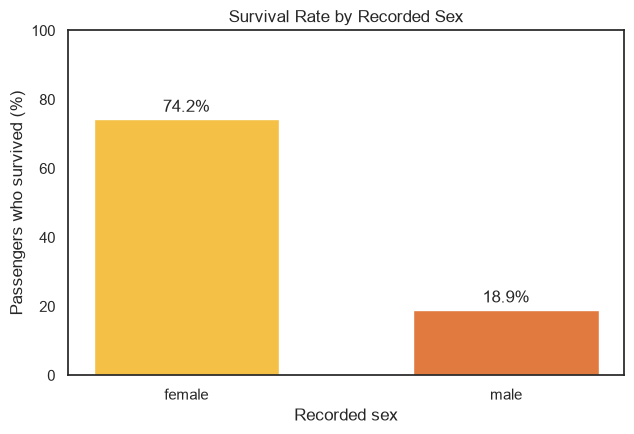

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(sex_summary["Sex"].astype(str), sex_summary["Survival (%)"],
              color=[YELLOW, ORANGE], width=0.58)
ax.set_title("Survival Rate by Recorded Sex")
ax.set_xlabel("Recorded sex")
ax.set_ylabel("Passengers who survived (%)")
ax.set_ylim(0, 100)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in sex_summary["Survival (%)"]], padding=3)
plt.tight_layout()
plt.savefig("../RESULTS/Survival_by_sex.png", dpi=150)
plt.show()

In [10]:
sex_table = pd.crosstab(titanic["Sex"], titanic["Survived"])
sex_chi2, sex_p, sex_dof, sex_expected = stats.chi2_contingency(sex_table)
n = sex_table.to_numpy().sum()
r, k = sex_table.shape
sex_cramers_v = np.sqrt(sex_chi2 / (n * min(r - 1, k - 1)))

print("Observed counts (rows = recorded sex; columns = survival outcome):")
display(sex_table)
print(f"Chi-square statistic: {sex_chi2:.3f}")
print(f"Degrees of freedom: {sex_dof}")
print(f"p-value: {sex_p:.6g}")
print(f"Cramér's V: {sex_cramers_v:.3f}")

Observed counts (rows = recorded sex; columns = survival outcome):


Survived,0,1
Sex,,
female,81,233
male,468,109


Chi-square statistic: 260.717
Degrees of freedom: 1
p-value: 1.19736e-58
Cramér's V: 0.541


## Interpretation:
The results show a clear difference in survival rates between female and male passengers. About 74.2% of female passengers survived, compared to only 18.9% of male passengers.

The chi-square test gave a p-value much smaller than 0.05, so I reject the null hypothesis. This suggests that recorded sex was associated with survival in the Titanic dataset. Cramér's V was 0.541, which indicates a considerable association.

## 4. Hypothesis 3 - Aged and survival
**Research question:** Do age distributions differ between passengers who survived and those who did not?
- H₀: The age distributions are the same for the two survival groups.
- H₁: The age distributions differ.
I will use a histogram and a boxplot to compare the groups, followed by a Mann–Whitney U test. Only passengers with a recorded age will be included.

In [11]:
age_data = titanic[["Age", "Survived"]].dropna(subset=["Age"]).copy()
age_data["Survival outcome"] = age_data["Survived"].map({0: "Did not survive", 1: "Survived"})

age_summary = (
    age_data.groupby("Survival outcome")["Age"]
    .agg(Passengers="count", Mean_age="mean", Median_age="median", Std_age="std")
    .round(2)
)
display(age_summary)
print(f"Passengers with known age: {len(age_data)}")
print(f"Passengers excluded due to missing age: {titanic['Age'].isna().sum()}")

,Passengers,Mean_age,Median_age,Std_age
Survival outcome,,,,
Did not survive,424,30.63,28.0,14.17
Survived,290,28.34,28.0,14.95


Passengers with known age: 714
Passengers excluded due to missing age: 177


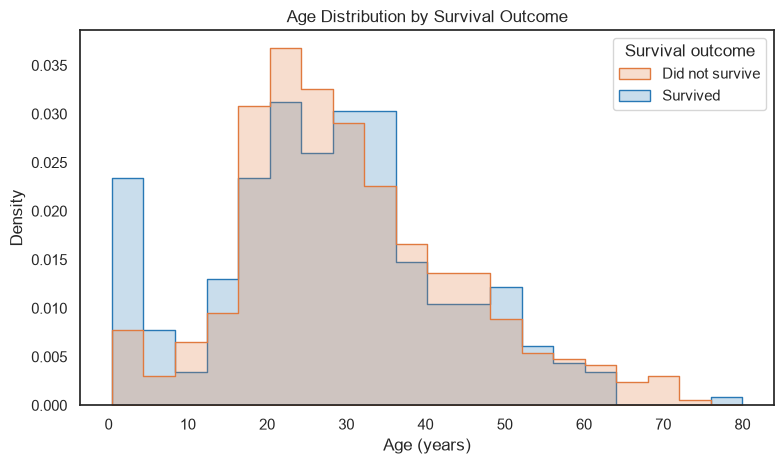

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(data=age_data, x="Age", hue="Survival outcome",
             bins=20, stat="density", common_norm=False,
             element="step", fill=True, alpha=0.25,
             palette={"Did not survive": ORANGE, "Survived": BLUE}, ax=ax)
ax.set_title("Age Distribution by Survival Outcome")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Density")
plt.tight_layout()
plt.savefig("../RESULTS/Age_distribution.png", dpi=150)
plt.show()

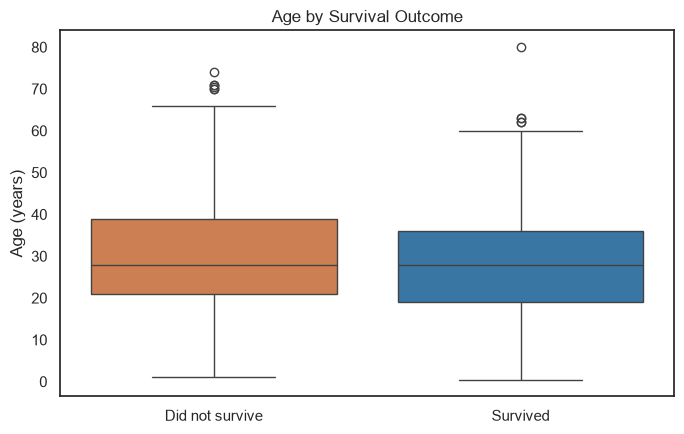

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))

sns.boxplot(
    data=age_data,
    x="Survival outcome",
    y="Age",
    hue="Survival outcome",
    order=["Did not survive", "Survived"],
    hue_order=["Did not survive", "Survived"],
    palette={
        "Did not survive": ORANGE,
        "Survived": BLUE
    },
    legend=False,
    ax=ax
)

ax.set_title("Age by Survival Outcome")
ax.set_xlabel("")
ax.set_ylabel("Age (years)")

plt.tight_layout()
plt.savefig("../RESULTS/Age_boxplot.png", dpi=150)
plt.show()

In [14]:
survivor_ages = age_data.loc[age_data["Survived"] == 1, "Age"]
non_survivor_ages = age_data.loc[age_data["Survived"] == 0, "Age"]
u_stat, age_p = stats.mannwhitneyu(survivor_ages, non_survivor_ages, alternative="two-sided")

print(f"Mann–Whitney U statistic: {u_stat:.1f}")
print(f"p-value: {age_p:.6g}")
print(f"Median age among survivors: {survivor_ages.median():.1f}")
print(f"Median age among non-survivors: {non_survivor_ages.median():.1f}")

Mann–Whitney U statistic: 57682.0
p-value: 0.160493
Median age among survivors: 28.0
Median age among non-survivors: 28.0


## Interpretation:
The median age was 28 years for both survivors and non-survivors. The Mann–Whitney U test gave a p-value of 0.1605, which is higher than 0.05.

Therefore, I do not reject the null hypothesis. Based on this test, there is not enough statistical evidence to conclude that the age distributions were different between the two groups.

However, this does not mean that age had no relationship with survival. It only means that this analysis did not find a statistically significant difference.

## Summary of hypothesis tests

In [15]:
results = pd.DataFrame([
    {"Hypothesis": "H1: Passenger class", "Test": "Chi-square",
     "Statistic": class_chi2, "p-value": class_p, "Effect size (Cramér's V)": class_cramers_v},
    {"Hypothesis": "H2: Recorded sex", "Test": "Chi-square",
     "Statistic": sex_chi2, "p-value": sex_p, "Effect size (Cramér's V)": sex_cramers_v},
    {"Hypothesis": "H3: Age", "Test": "Mann–Whitney U",
     "Statistic": u_stat, "p-value": age_p, "Effect size (Cramér's V)": np.nan}
])
results["Decision (α = 0.05)"] = np.where(results["p-value"] < 0.05, "Reject H₀", "Do not reject H₀")
display(results.round(4))

,Hypothesis,Test,Statistic,p-value,Effect size (Cramér's V),Decision (α = 0.05)
0,H1: Passenger class,Chi-square,102.889,0.0000,0.3398,Reject H₀
1,H2: Recorded sex,Chi-square,260.717,0.0000,0.5409,Reject H₀
2,H3: Age,Mann–Whitney U,57682.000,0.1605,NaN,Do not reject H₀


## Conclusion:
Who survived the Titanic? Mostly women, passengers in first and second class, and young children. Most of those who died were adult men travelling in third class.

1. Sex was the strongest factor (V = 0.54): 74.2% of female passengers survived compared with 18.9% of male passengers, consistent with the “women and children first” policy.
2. Class had a moderate association (V = 0.34): survival fell from 63.0% in first class to 24.2% in third class.
3. Age showed no significant overall difference (median 28 in both groups)

## Limitations:
*These results show association, not causation (class is also linked to cabin location and how close passengers were to the lifeboats); 177 passengers (19.9%) had no recorded age; and the dataset includes 891 of the roughly 2,200 people aboard.*